## Inicjalizacja danych i zmiennych

In [ ]:
import random
import numpy as np

POPULATION_SIZE = 40
GENERATIONS = 100
MUTATION_RATE = 0.15

## Implementacja algorytmu genetycznego

In [41]:
def run_genetic_algorithm(path: str):
    # 1. Wczytanie danych dla konkretnego pliku
    data = np.genfromtxt(path, delimiter=",", dtype=np.str_)

    PLAYER_NAMES = data[:, 0].copy()
    STATISTICS = data[:, 1:].astype(np.float64).copy()

    NUM_PLAYERS = len(PLAYER_NAMES)
    TEAM_AMOUNT = NUM_PLAYERS // 3
    STATISTICS_AMOUNT = STATISTICS.shape[1]
    WEIGHTS = np.ones(STATISTICS_AMOUNT)

    def calculate_fitness(chromosome):
        """
        Ocena zbalansowania drużyn. Im mniejsza różnica punktowa, tym wyższy fitness.
        """
        if len(set(chromosome)) != NUM_PLAYERS:
            return float("inf")  # Silna kara za powtórki w drużynach.

        fitness = 0
        for j in range(STATISTICS_AMOUNT):
            mu = np.mean(STATISTICS[:, j])
            w = WEIGHTS[j]

            for i in range(TEAM_AMOUNT):
                p1, p2, p3 = chromosome[3*i:3*i+3]
                avg = (STATISTICS[p1-1, j] + STATISTICS[p2-1, j] + STATISTICS[p3-1, j]) / 3
                fitness += w * (avg - mu)**2

        return fitness


    def create_individual():
        """Tworzy osobnik z ciągiem liczb od 1 do NUM_PLAYERS."""
        chromosome = list(range(1, NUM_PLAYERS+1))
        random.shuffle(chromosome)
        return chromosome


    def crossover(parent1, parent2):
        """Krzyżowanie jednopunktowe z naprawą powtórek."""
        point = random.randint(1, NUM_PLAYERS - 1)
        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]

        # Naprawa child1
        count = np.bincount(child1, minlength=NUM_PLAYERS + 1)
        missing = np.nonzero(count[1:] < 1)[0] + 1
        
        for value in missing:
            count = np.bincount(child1, minlength=NUM_PLAYERS + 1)
            duplicates = np.nonzero(count[1:] > 1)[0] + 1
            if len(duplicates) > 0:
                idx = np.where(np.array(child1) == duplicates[0])[0][0]
                child1[idx] = value

        # Naprawa child2
        count = np.bincount(child2, minlength=NUM_PLAYERS + 1)
        missing = np.nonzero(count[1:] < 1)[0] + 1
        
        for value in missing:
            count = np.bincount(child2, minlength=NUM_PLAYERS + 1)
            duplicates = np.nonzero(count[1:] > 1)[0] + 1
            if len(duplicates) > 0:
                idx = np.where(np.array(child2) == duplicates[0])[0][0]
                child2[idx] = value

        return child1, child2


    def mutate(chromosome):
        """Mutacja typu Swap: zamienia miejscami dwóch graczy."""
        if random.random() < MUTATION_RATE:
            idx_a, idx_b = np.random.choice(list(range(NUM_PLAYERS)), size=2, replace=False)
            chromosome[idx_a], chromosome[idx_b] = chromosome[idx_b], chromosome[idx_a]
        return chromosome

    # Inicjalizacja populacji
    population = [create_individual() for _ in range(POPULATION_SIZE)]

    best_solution = None
    best_fitness = float("inf")

    for generation in range(GENERATIONS):
        new_population = population.copy()
        new_population.sort(key=lambda x: calculate_fitness(x))

        for i in range(0, POPULATION_SIZE, 2):
            p1 = new_population[i]
            p2 = new_population[i+1]
            child1, child2 = crossover(p1, p2)
            child1 = mutate(child1)
            child2 = mutate(child2)
            new_population.append(child1)
            new_population.append(child2)

        new_population.sort(key=lambda x: calculate_fitness(x))
        population = new_population[:POPULATION_SIZE]

        min_fit = calculate_fitness(population[0])
        if min_fit < best_fitness:
            best_fitness = min_fit
            best_solution = population[0]

    return best_solution, best_fitness, PLAYER_NAMES, STATISTICS

## Wypisanie składów drużyn

In [ ]:
for players in [12, 24, 48]:
        fitnesses = []
        for version in [1, 2, 3]:
            # Odbieramy również lokalne PLAYER_NAMES i STATISTICS
            best_chrom, fitness, PLAYER_NAMES, STATISTICS = run_genetic_algorithm(f"{players}_gracze_v{version}.csv")
            amount = int(players / 3)
            print(amount)
            print("=== Wynik Optymalizacji Turnieju Bocce ===", f"{players}_gracze_v{version}.csv")
            for team in range(amount):
                print(50*"=-")
                print(f"Drużyna {team + 1}:")
                p1, p2, p3 = best_chrom[3*team], best_chrom[3*team + 1], best_chrom[3*team + 2]
                print(f" - {PLAYER_NAMES[p1 - 1]} -> {STATISTICS[p1 - 1]}")
                print(f" - {PLAYER_NAMES[p2 - 1]} -> {STATISTICS[p2 - 1]}")
                print(f" - {PLAYER_NAMES[p3 - 1]} -> {STATISTICS[p3 - 1]}")
                print(f"Average team statistics: {np.mean(STATISTICS[[p1 - 1, p2 - 1, p3 - 1]], axis=0)}")
                print("\n\n")
            
            print(f"Najlepszy osobnik: {best_chrom}")
            print(f"O wartości przystosowania: {fitness}")

4
=== Wynik Optymalizacji Turnieju Bocce === 12_gracze_v1.csv
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
Drużyna 1:
 - Mateusz Słupkowski/a -> [0.56631 0.4486  0.33519 0.51675 0.5109  0.37726 0.43168]
 - Paweł Słupkowski/a -> [0.35182 0.489   0.45542 0.57753 0.51936 0.33692 0.38048]
 - Mateusz Ulatowski/a -> [0.52136 0.52173 0.71178 0.3888  0.46224 0.70428 0.56467]
Average team statistics: [0.47983    0.48644333 0.50079667 0.49436    0.4975     0.47282
 0.45894333]
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
Drużyna 2:
 - Mateusz Wierzejewski/a -> [0.45179 0.55988 0.50397 0.47075 0.42181 0.47428 0.50081]
 - Paweł Wierzejewski/a -> [0.59145 0.49799 0.37513 0.46861 0.50541 0.52728 0.40178]
 - Mateusz Piotrowski/a -> [0.55811 0.53646 0.52941 0.50284 0.55467 0.42635 0.48371]
Average team statistics: [0.53378333 0.53144333 0.46950333 0.48073333 0.49396333 0.47597
 0.4621    ]
=

## Obliczenie średnich błędów

In [43]:
for players in [12, 24, 48]:
    fitnesses = []
    for version in [1, 2, 3]:
        for iteration in range(10): # można zamienić 10 na 30
            # Odbieramy 4 wartości, ale potrzebujemy tylko best_chrom i fitness
            best_chrom, fitness, _, _ = run_genetic_algorithm(f"{players}_gracze_v{version}.csv")
            fitnesses.append(fitness)
    print(f"Players {players} average fitness: {np.mean(fitnesses)}")

Players 12 average fitness: 0.014617688004444433
Players 24 average fitness: 0.04204677736675925
Players 48 average fitness: 0.10325533705680554


## Porównanie wyników 

Znaleziono 9 unikalnych plików projektu!

---> Liczę dla: 12_gracze_v1.csv <---
   Wynik -> Losowy: 0.05389 | PyGAD: 0.00997 | Nasz GA: 0.00997

---> Liczę dla: 12_gracze_v2.csv <---
   Wynik -> Losowy: 0.06655 | PyGAD: 0.01540 | Nasz GA: 0.01958

---> Liczę dla: 12_gracze_v3.csv <---
   Wynik -> Losowy: 0.07784 | PyGAD: 0.01679 | Nasz GA: 0.01875

---> Liczę dla: 24_gracze_v1.csv <---
   Wynik -> Losowy: 0.12728 | PyGAD: 0.03750 | Nasz GA: 0.03447

---> Liczę dla: 24_gracze_v2.csv <---
   Wynik -> Losowy: 0.14534 | PyGAD: 0.04853 | Nasz GA: 0.03081

---> Liczę dla: 24_gracze_v3.csv <---
   Wynik -> Losowy: 0.18121 | PyGAD: 0.06400 | Nasz GA: 0.05253

---> Liczę dla: 48_gracze_v1.csv <---
   Wynik -> Losowy: 0.28937 | PyGAD: 0.14302 | Nasz GA: 0.10334

---> Liczę dla: 48_gracze_v2.csv <---
   Wynik -> Losowy: 0.35324 | PyGAD: 0.17262 | Nasz GA: 0.11388

---> Liczę dla: 48_gracze_v3.csv <---
   Wynik -> Losowy: 0.35054 | PyGAD: 0.16959 | Nasz GA: 0.11955

Gracze     | Losowy (Baseline) 

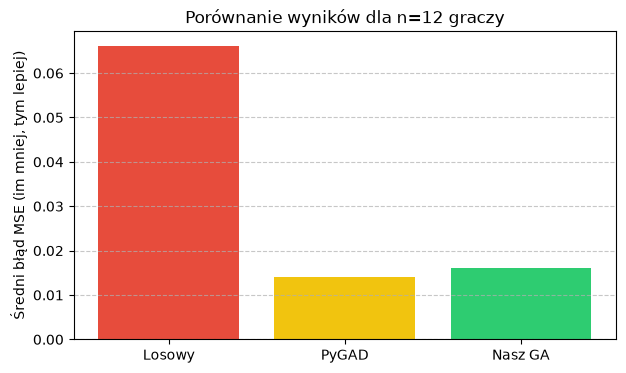

24         | 0.15128              | 0.05001         | 0.03927        


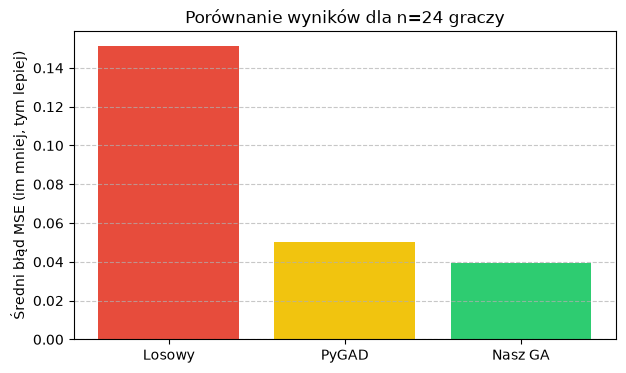

48         | 0.33105              | 0.16174         | 0.11226        


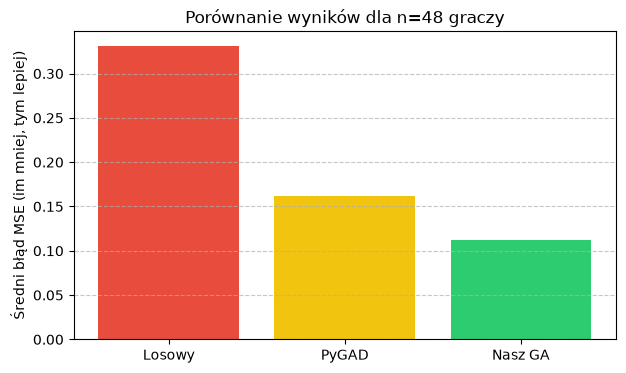

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import pygad
import glob
import os
import random

# Parametry naszego algorytmu genetycznego
POPULATION_SIZE = 40
GENERATIONS = 100
MUTATION_RATE = 0.15

# 1. Funkcja obliczająca błąd MSE
def oblicz_mse(permutacja, statystyki):
    n = len(permutacja)
    liczba_druzyn = n // 3
    zreorganizowani = statystyki[permutacja - 1]  # Dopasowanie indeksów 1-based do 0-based
    druzyny = zreorganizowani.reshape(liczba_druzyn, 3, 7)
    
    srednia_druzyn = np.mean(druzyny, axis=1)
    mu_j = np.mean(statystyki, axis=0)
    
    mse = np.sum((srednia_druzyn - mu_j) ** 2)
    return mse

# 2. Metoda losowa (1000 prób)
def losowy_podzial(statystyki, ilosc_prob=1000):
    n = len(statystyki)
    wyniki = []
    for _ in range(ilosc_prob):
        perm = np.random.permutation(n) + 1  # 1-based indexing
        wyniki.append(oblicz_mse(perm, statystyki))
    return np.mean(wyniki)

# 3. Metoda PyGAD
def uruchom_pygad(statystyki):
    n = len(statystyki)
    
    def fitness_func(ga_instance, solution, solution_idx):
        # PyGAD używa 0-based, konwertujemy na 1-based dla oblicz_mse
        score = oblicz_mse(solution.astype(int) + 1, statystyki)
        return 1.0 / (1.0 + score)

    ga_instance = pygad.GA(
        num_generations=50,
        num_parents_mating=8,
        fitness_func=fitness_func,
        sol_per_pop=30,
        num_genes=n,
        gene_type=int,
        gene_space=list(range(n)),
        allow_duplicate_genes=False,
        suppress_warnings=True
    )
    
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    najlepsze_mse = (1.0 / solution_fitness) - 1.0
    return najlepsze_mse


if __name__ == "__main__":
    current_dir = "./"
    
    szukane_pliki = []
    for n_graczy in [12, 24, 48]:
        for v in [1, 2, 3]:
            wzorzec = os.path.join(current_dir, "**", f"{n_graczy}_gracze_v{v}.csv")
            dopasowania = glob.glob(wzorzec, recursive=True)
            if dopasowania:
                szukane_pliki.append(dopasowania[0])

    print(f"Znaleziono {len(szukane_pliki)} unikalnych plików projektu!")
    
    wyniki_grupa = {}
    
    for plik in szukane_pliki:
        nazwa_pliku = os.path.basename(plik)
        print(f"\n---> Liczę dla: {nazwa_pliku} <---")
        
        try:
            statystyki_temp = np.loadtxt(plik, delimiter=",", usecols=range(1, 8), dtype=float)
        except Exception as e:
            print(f"Błąd odczytu {nazwa_pliku}: {e}")
            continue
            
        n = len(statystyki_temp)
        
        mse_losowe = losowy_podzial(statystyki_temp, 1000)
        mse_pygad = uruchom_pygad(statystyki_temp)
        
        # Używamy Twojej funkcji przyjmującej ścieżkę do pliku
        _, mse_nasz, _, _ = run_genetic_algorithm(plik)
        
        if n not in wyniki_grupa:
            wyniki_grupa[n] = {"los": [], "pygad": [], "nasz": []}
            
        wyniki_grupa[n]["los"].append(mse_losowe)
        wyniki_grupa[n]["pygad"].append(mse_pygad)
        wyniki_grupa[n]["nasz"].append(mse_nasz)
        
        print(f"   Wynik -> Losowy: {mse_losowe:.5f} | PyGAD: {mse_pygad:.5f} | Nasz GA: {mse_nasz:.5f}")
    
    print("\n" + "="*65)
    print(f"{'Gracze':<10} | {'Losowy (Baseline)':<20} | {'PyGAD':<15} | {'Nasz Algorytm':<15}")
    print("="*65)
    
    for n in sorted(wyniki_grupa.keys()):
        srednia_los = np.mean(wyniki_grupa[n]["los"])
        srednia_pygad = np.mean(wyniki_grupa[n]["pygad"])
        srednia_nasz = np.mean(wyniki_grupa[n]["nasz"])
        
        print(f"{n:<10} | {srednia_los:<20.5f} | {srednia_pygad:<15.5f} | {srednia_nasz:<15.5f}")
        
        # Wykres słupkowy podsumowujący
        plt.figure(figsize=(7, 4))
        plt.bar(['Losowy', 'PyGAD', 'Nasz GA'], [srednia_los, srednia_pygad, srednia_nasz], color=['#e74c3c', '#f1c40f', '#2ecc71'])
        plt.ylabel('Średni błąd MSE (im mniej, tym lepiej)')
        plt.title(f'Porównanie wyników dla n={n} graczy')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        
        sciezka_wykresu = os.path.join(current_dir, f'wykres_porownanie_{n}_graczy.png')
        plt.savefig(sciezka_wykresu)
        plt.show()
        plt.close()